# 05 - Model comparison, selection and the final model

**Goal:** compare the two Optuna-tuned models fairly on the **same untouched test set**, select the final model (highest test Macro-F1), check whether the difference is statistically meaningful, explain the result, and save/register the final model.

Inputs: `artifacts/comparison/<config>_<model>/result.json` and the saved models from notebooks 03 and 04.
Outputs: comparison tables/plots in `artifacts/comparison/`, `artifacts/final_model.json`, an `SDSS17-Final` MLflow run with the registered model `sdss17-final-classifier`, and `artifacts/mlflow_runs.csv`.

## 1. Setup and load the results of notebooks 03 and 04

In [1]:
import sys, warnings, json
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")          # shared helpers live in src/common.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from common import (ROOT, ART, SEED, CLASSES, MAGS, COLORS, ID_COLS, SKY_COLS, FEATURE_SETS, PALETTE,
                    load_raw, clean, add_color_indices, make_splits, mlflow_experiment)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

import joblib
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score
from common import compute_metrics, conf_mat, plot_cm
CMP, MODELS_DIR = ART / "comparison", ART / "models"

R = {(cfg, name): json.loads((CMP / f"{cfg}_{name}" / "result.json").read_text())
     for cfg in ("with_redshift", "without_redshift") for name in ("catboost", "lightgbm")}
print("loaded:", list(R))

df, _ = clean(load_raw()); S = make_splits(df)
yte = S["test"]["y"].values
print("test set:", S["test"].shape, "(never used for tuning)")

loaded: [('with_redshift', 'catboost'), ('with_redshift', 'lightgbm'), ('without_redshift', 'catboost'), ('without_redshift', 'lightgbm')]


test set: (15000, 23) (never used for tuning)


## 2. Metrics table (validation and test)
Accuracy, Macro-F1, Weighted-F1, Precision and Recall (macro- and weighted-averaged), plus per-class F1.
* **Macro** average = each class counts equally (the fair metric under class imbalance; this is the selection metric).
* **Weighted** average = classes weighted by their frequency (close to accuracy).

In [2]:
rows = [{"config": c, "model": n, "split": sp, **r[sp]} for (c, n), r in R.items() for sp in ("val", "test")]
mt = pd.DataFrame(rows); mt.to_csv(CMP / "metrics_all.csv", index=False)
cols = ["accuracy", "macro_f1", "weighted_f1", "precision_macro", "recall_macro", "precision_weighted", "recall_weighted"]
print("TEST - with redshift (main comparison)")
display(mt.query("split == 'test' and config == 'with_redshift'").set_index("model")[cols].round(4))
print("VALIDATION - with redshift (what Optuna optimised)")
display(mt.query("split == 'val' and config == 'with_redshift'").set_index("model")[cols].round(4))

TEST - with redshift (main comparison)


,accuracy,macro_f1,weighted_f1,precision_macro,recall_macro,precision_weighted,recall_weighted
model,,,,,,,
catboost,0.9782,0.9749,0.9781,0.9765,0.9734,0.9781,0.9782
lightgbm,0.9805,0.9773,0.9804,0.9796,0.9750,0.9804,0.9805


VALIDATION - with redshift (what Optuna optimised)


,accuracy,macro_f1,weighted_f1,precision_macro,recall_macro,precision_weighted,recall_weighted
model,,,,,,,
catboost,0.9777,0.9742,0.9776,0.9775,0.9711,0.9776,0.9777
lightgbm,0.9789,0.9754,0.9788,0.9788,0.9722,0.9788,0.9789


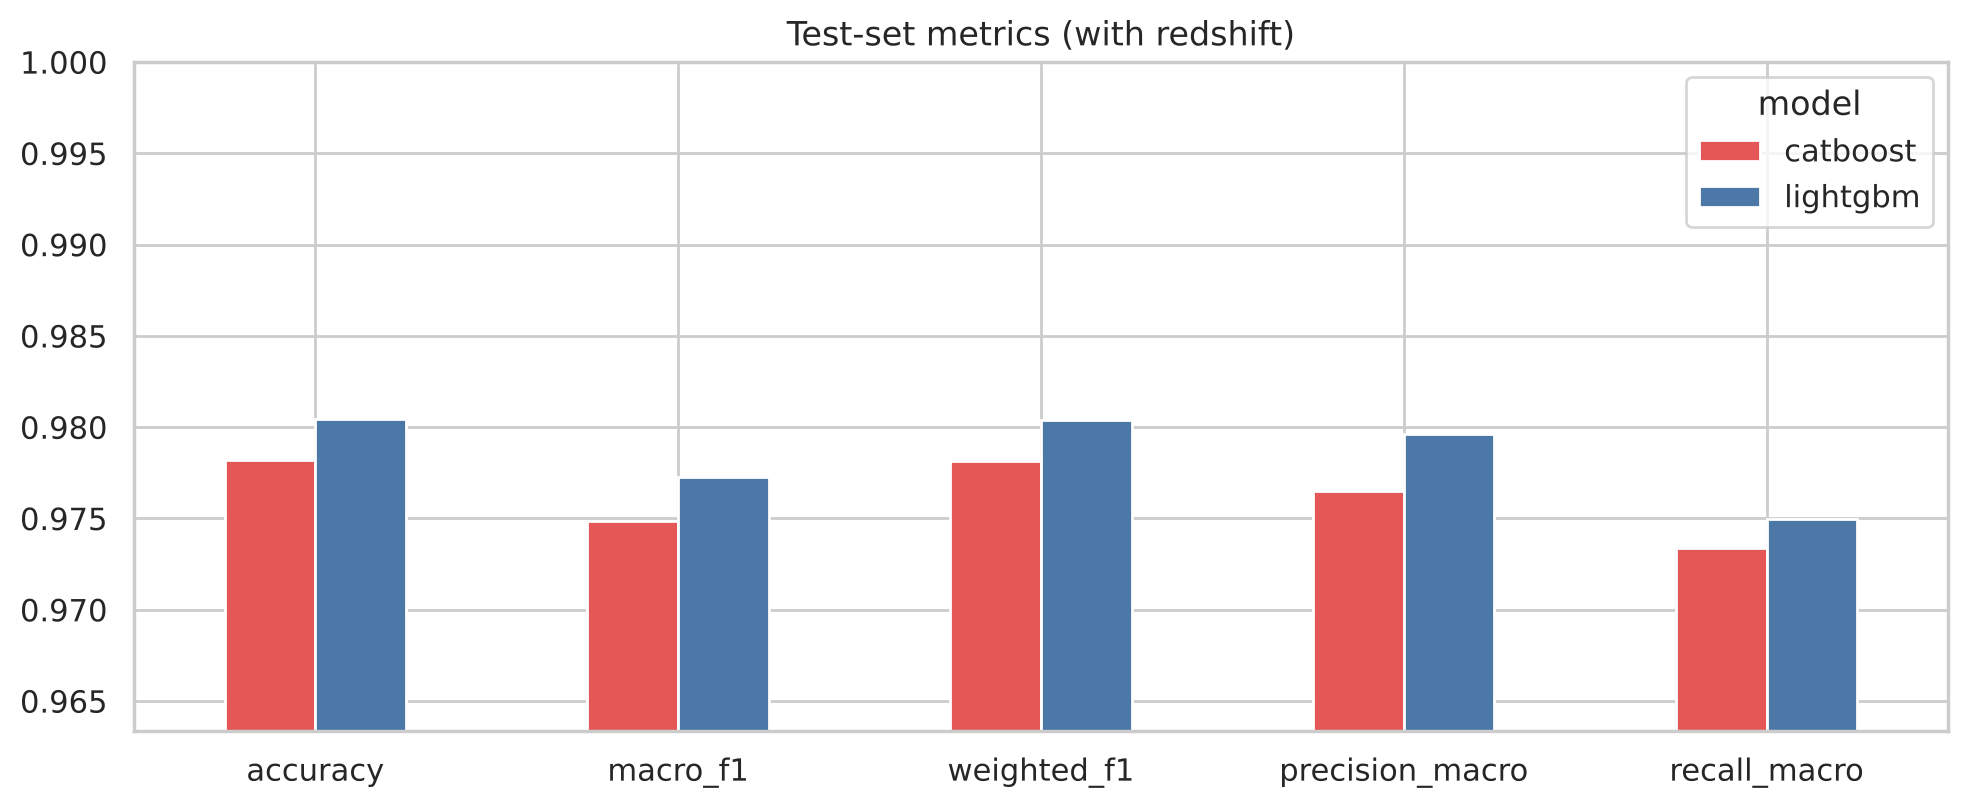

In [3]:
t = mt.query("split == 'test' and config == 'with_redshift'").set_index("model")
fig, ax = plt.subplots(figsize=(10, 4.2))
t[cols[:5]].T.plot.bar(ax=ax, color=["#e45756", "#4c78a8"] if t.index[0] == "catboost" else None)
ax.set_ylim(max(0.9, t[cols[:5]].values.min() - 0.01), 1.0); ax.set_title("Test-set metrics (with redshift)"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(CMP / "metrics_comparison.png", dpi=130); plt.show()

**Reading:** both models are excellent and very close - the bars differ in the third decimal. LightGBM is slightly ahead on every aggregate metric. Because the gap is tiny, we test below whether it is statistically real.

## 3. Confusion matrices on the test set
Rows = true class, columns = predicted class; the right-hand panel is row-normalised (= per-class recall).

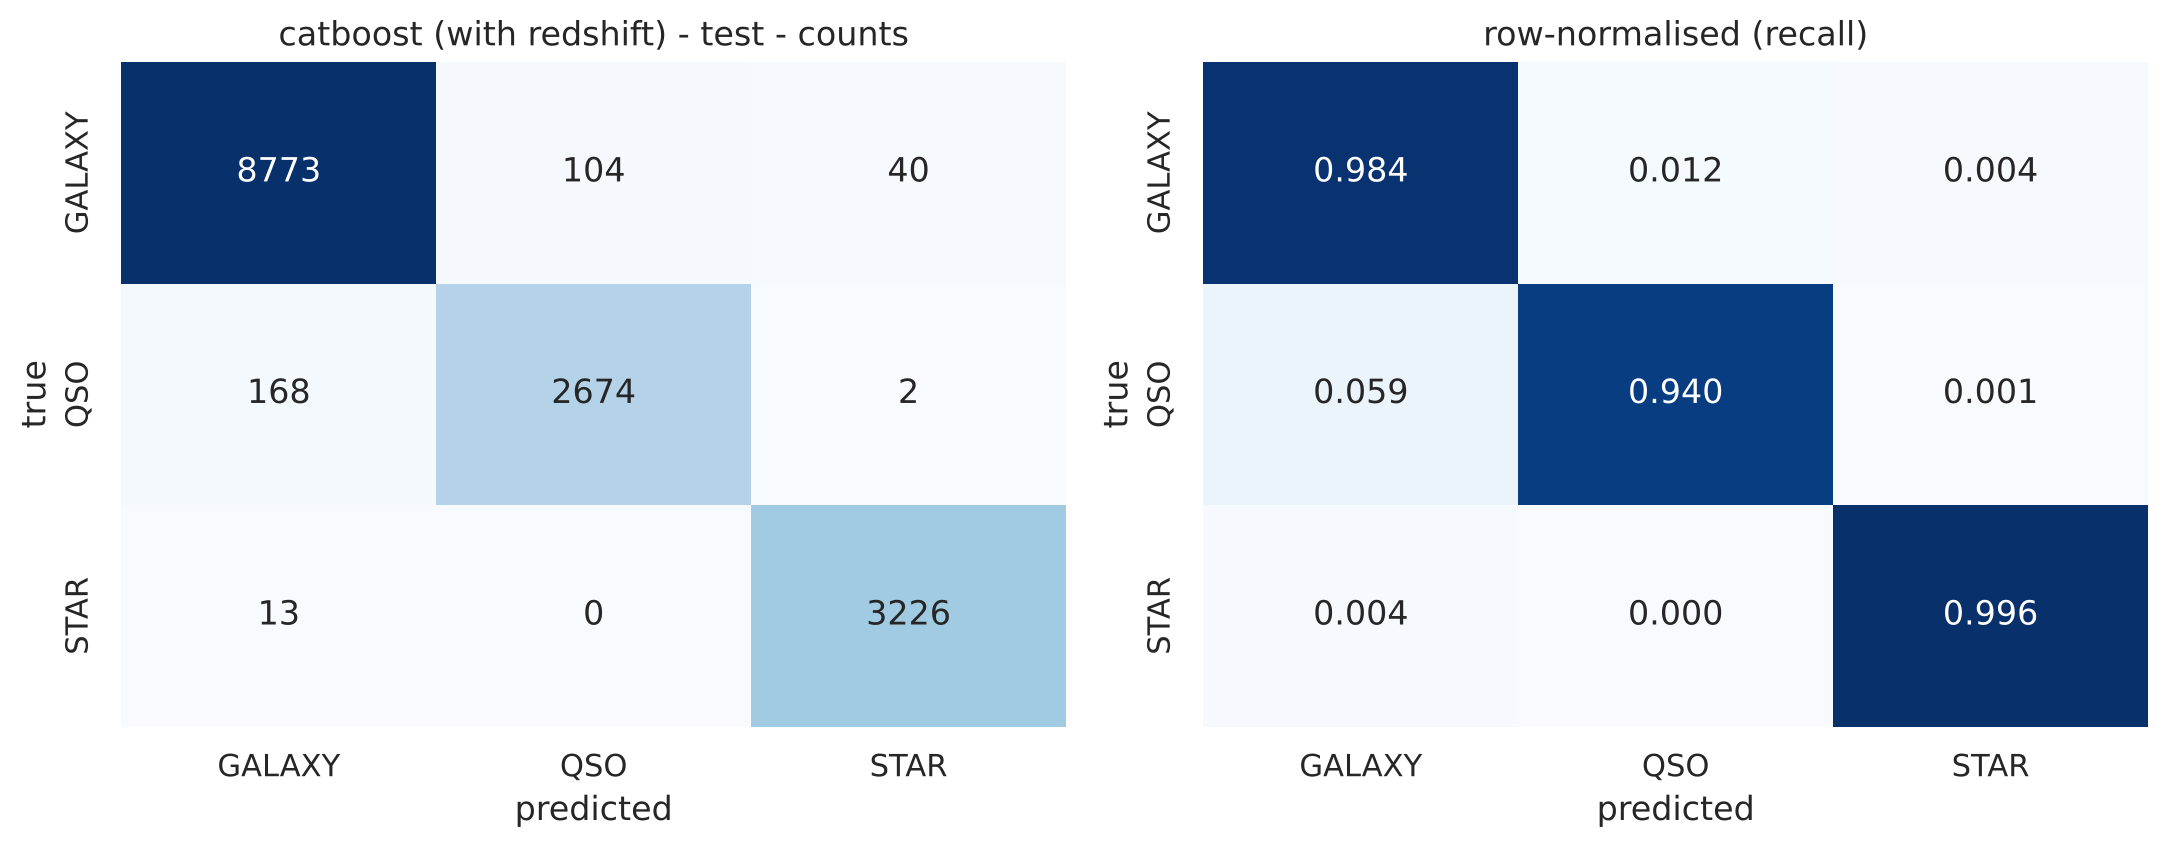

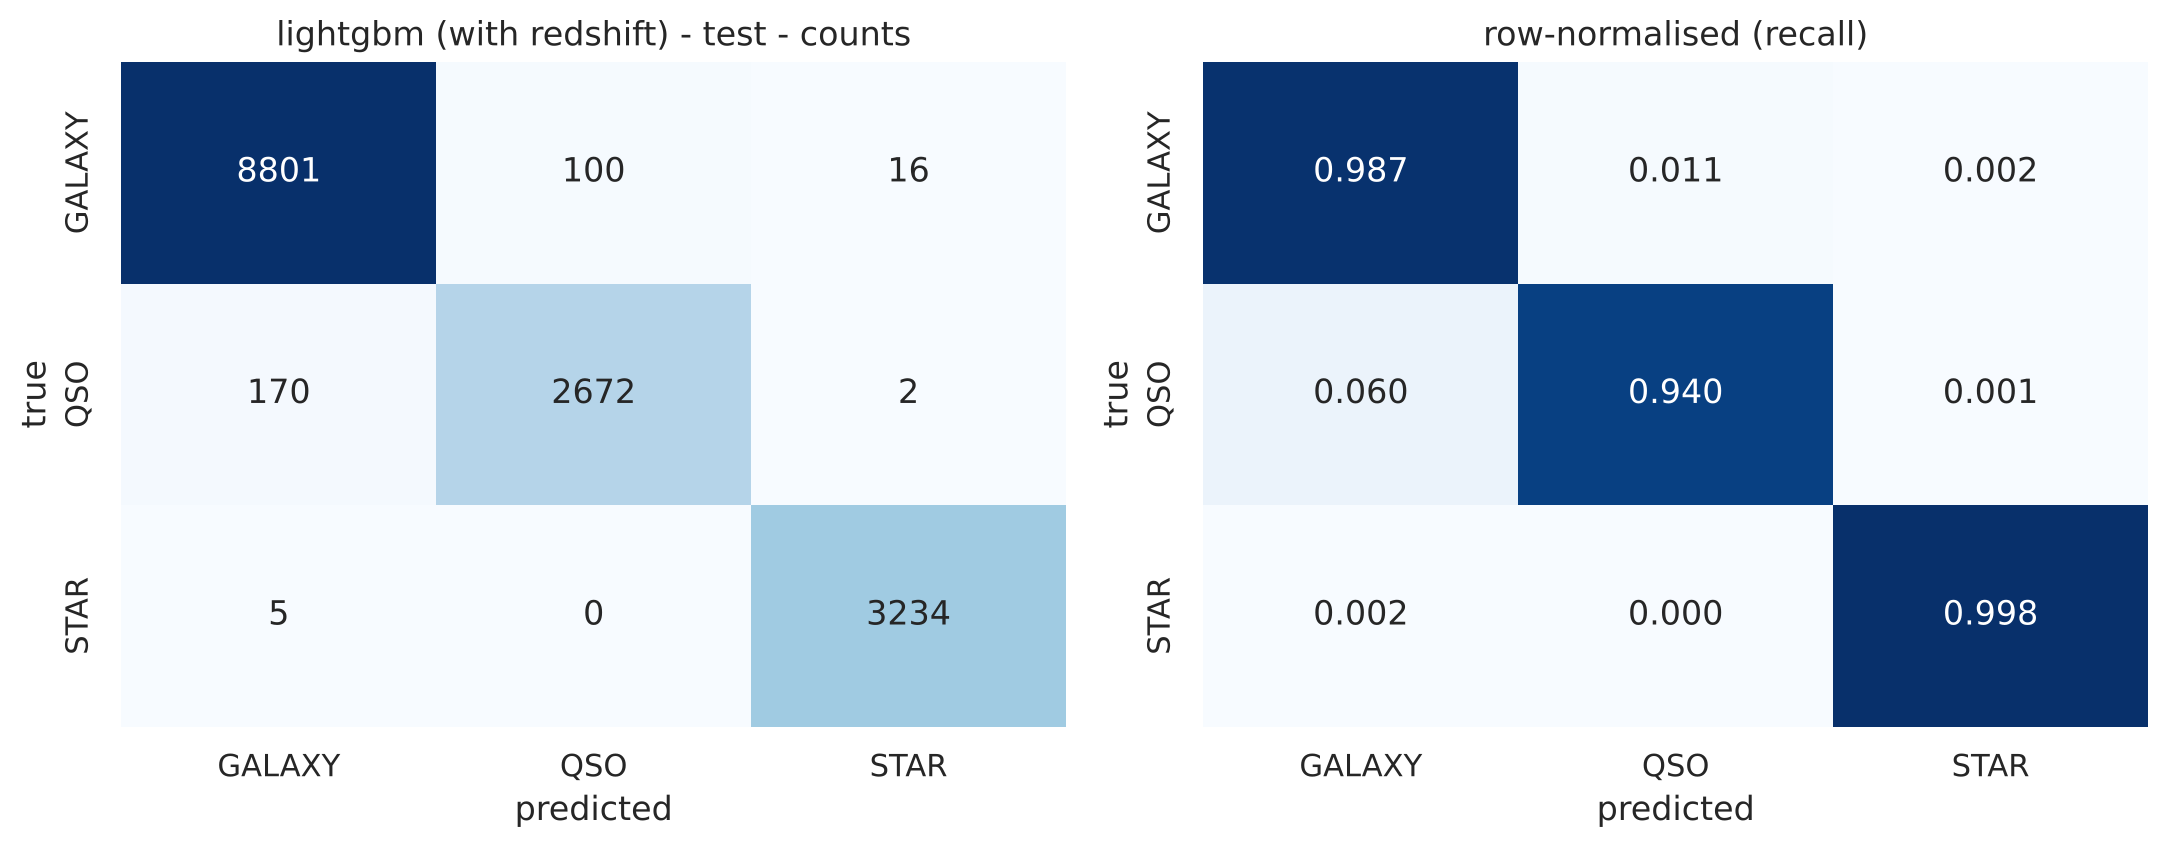

,f1_GALAXY,f1_QSO,f1_STAR
model,,,
catboost,0.9818,0.9513,0.9915
lightgbm,0.9837,0.9516,0.9965


In [4]:
for name in ("catboost", "lightgbm"):
    cm = np.array(R[("with_redshift", name)]["confusion_matrix_test"])
    plot_cm(cm, f"{name} (with redshift) - test")
display(mt.query("split == 'test' and config == 'with_redshift'").set_index("model")[[f"f1_{c}" for c in CLASSES]].round(4))

**Reading:** both models make most of their mistakes (83 % for CatBoost, 92 % for LightGBM) between **QSO and GALAXY** (distant quasars versus compact galaxies look alike), while stars are almost perfectly recognised. The per-class F1 table shows that LightGBM's advantage comes mostly from the STAR class, with QSO and GALAXY roughly tied.

## 4. Selecting the final model
**Rule (as specified):** the final model is the one with the highest **test Macro-F1** among the two Optuna-tuned models (main configuration, with redshift). Hyper-parameters were chosen on the *validation* set only, so the test set has played no role in tuning; it is used here for the one-time comparison and selection.

First we regenerate the test predictions of both saved models (this also verifies that the saved model files work).

In [5]:
feats = FEATURE_SETS["with_redshift"]
cb = CatBoostClassifier(); cb.load_model(str(MODELS_DIR / "with_redshift_catboost.cbm"))
lg = joblib.load(MODELS_DIR / "with_redshift_lightgbm.joblib")
pred = {"catboost": np.asarray(cb.predict(S["test"][feats])).ravel().astype(int),
        "lightgbm": np.asarray(lg.predict(S["test"][feats])).ravel().astype(int)}
for n, p in pred.items():
    print(f"{n:9s} test Macro-F1 recomputed = {f1_score(yte, p, average='macro'):.4f}  (stored: {R[('with_redshift', n)]['test']['macro_f1']:.4f})")

winner = max(pred, key=lambda n: R[("with_redshift", n)]["test"]["macro_f1"])
runner = "lightgbm" if winner == "catboost" else "catboost"
print("\nSELECTED FINAL MODEL:", winner.upper())

catboost  test Macro-F1 recomputed = 0.9749  (stored: 0.9749)
lightgbm  test Macro-F1 recomputed = 0.9773  (stored: 0.9773)

SELECTED FINAL MODEL: LIGHTGBM


### Is the difference real? Paired bootstrap
With 15,000 test rows, a 0.002 difference in Macro-F1 could be luck. We resample the test set 1,000 times (with replacement), compute the Macro-F1 difference *on the same resampled rows* for both models, and look at the 95 % interval. If the interval excludes 0 the winner is better beyond sampling noise (on this data distribution).

mean difference +0.0023, 95% CI [+0.0009, +0.0039]
the two models predict differently on 102 of 15,000 test objects


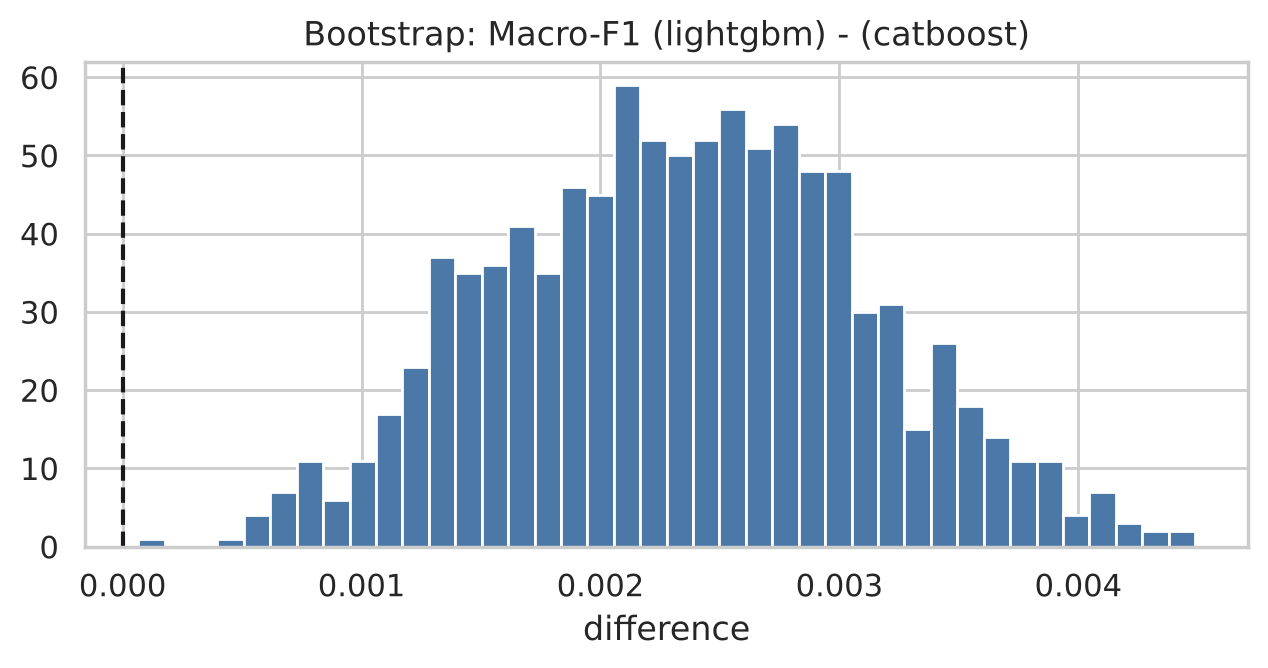

In [6]:
rs = np.random.RandomState(SEED); diffs = []
for _ in range(1000):
    i = rs.randint(0, len(yte), len(yte))
    diffs.append(f1_score(yte[i], pred[winner][i], average="macro") - f1_score(yte[i], pred[runner][i], average="macro"))
boot = {"mean_diff_macro_f1": float(np.mean(diffs)), "ci95": [float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))], "n_boot": 1000}
disagree = int((pred[winner] != pred[runner]).sum())
print(f"mean difference {boot['mean_diff_macro_f1']:+.4f}, 95% CI [{boot['ci95'][0]:+.4f}, {boot['ci95'][1]:+.4f}]")
print(f"the two models predict differently on {disagree} of {len(yte):,} test objects")
plt.figure(figsize=(6.5, 3.5)); plt.hist(diffs, bins=40, color="#4c78a8"); plt.axvline(0, color="k", ls="--")
plt.title(f"Bootstrap: Macro-F1 ({winner}) - ({runner})"); plt.xlabel("difference"); plt.tight_layout(); plt.show()

**Reading:** the whole interval is above zero, so the advantage is statistically distinguishable from zero - but it is **small** (a few tenths of a percentage point; ~100 objects out of 15,000 are classified differently). Practically the two models are near-equivalent; LightGBM wins on test Macro-F1 *and* trains about 7x faster (final fit ~7 s vs ~53 s).

## 5. Why did the winner perform better?
The explanation below is assembled from the measured numbers. The mechanism sentence is a **plausible reason, not a proven cause** - this experiment compares two tuned models, it does not isolate individual factors such as tree shape.

In [7]:
W, L = R[("with_redshift", winner)], R[("with_redshift", runner)]
dm = W["test"]["macro_f1"] - L["test"]["macro_f1"]; lo, hi = boot["ci95"]
cls_gap = {c: W["test"][f"f1_{c}"] - L["test"][f"f1_{c}"] for c in CLASSES}; best_c = max(cls_gap, key=cls_gap.get)
explanation = [
    f"**{winner.title()}** was selected: test Macro-F1 {W['test']['macro_f1']:.4f} vs {L['test']['macro_f1']:.4f} for {runner.title()} (difference {dm:+.4f}).",
    f"A paired bootstrap over the 15,000 test rows gives a 95% interval of [{lo:+.4f}, {hi:+.4f}] for that difference, so the gap is "
    + ("statistically distinguishable from zero." if lo > 0 else "**not statistically distinguishable from zero** - the models are effectively tied on this test set."),
    f"The two models disagree on {disagree} of {len(yte):,} test objects; the largest per-class F1 advantage of the winner is on {best_c} ({cls_gap[best_c]:+.4f}).",
]
hp = W["best_params"]
if winner == "catboost":
    explanation.append(f"Tuned configuration: depth {hp['depth']}, learning rate {hp['learning_rate']:.3f}, L2 {hp['l2_leaf_reg']:.2f}, {W['best_iteration']} trees. "
                       "CatBoost builds symmetric (oblivious) trees with ordered boosting, a strong regulariser that tends to help on low-dimensional, noisy photometric features - "
                       "a plausible reason for its edge, not something this experiment isolates.")
else:
    explanation.append(f"Tuned configuration: num_leaves {hp['num_leaves']}, max_depth {hp['max_depth']}, learning rate {hp['learning_rate']:.3f}, {W['best_iteration']} trees. "
                       "Leaf-wise growth lets LightGBM carve the sharp, non-linear decision boundaries of redshift/colour space (e.g. the QSO-vs-high-z-galaxy overlap) "
                       "with fewer, deeper splits - a plausible reason for its edge, not something this experiment isolates.")
top = list(W["feature_importance"].items())[:3]
explanation.append("Most influential features for the winner: " + ", ".join(f"{k} ({v:.1%})" for k, v in top) + ".")
explanation.append(f"Cost: final fit {W['final_fit_seconds']:.1f}s vs {L['final_fit_seconds']:.1f}s.")
from IPython.display import Markdown
display(Markdown("\n".join(f"- {e}" for e in explanation)))

- **Lightgbm** was selected: test Macro-F1 0.9773 vs 0.9749 for Catboost (difference +0.0024).
- A paired bootstrap over the 15,000 test rows gives a 95% interval of [+0.0009, +0.0039] for that difference, so the gap is statistically distinguishable from zero.
- The two models disagree on 102 of 15,000 test objects; the largest per-class F1 advantage of the winner is on STAR (+0.0049).
- Tuned configuration: num_leaves 49, max_depth 9, learning rate 0.035, 301 trees. Leaf-wise growth lets LightGBM carve the sharp, non-linear decision boundaries of redshift/colour space (e.g. the QSO-vs-high-z-galaxy overlap) with fewer, deeper splits - a plausible reason for its edge, not something this experiment isolates.
- Most influential features for the winner: redshift (64.2%), r-i (14.3%), g-r (6.3%).
- Cost: final fit 7.2s vs 52.6s.

## 6. Impact of redshift (with vs without)
The same two models, trained and tuned under the same protocol, on photometry-only features.

config,with_redshift,without_redshift,drop
model,,,
catboost,0.9749,0.8586,0.1163
lightgbm,0.9773,0.8595,0.1178


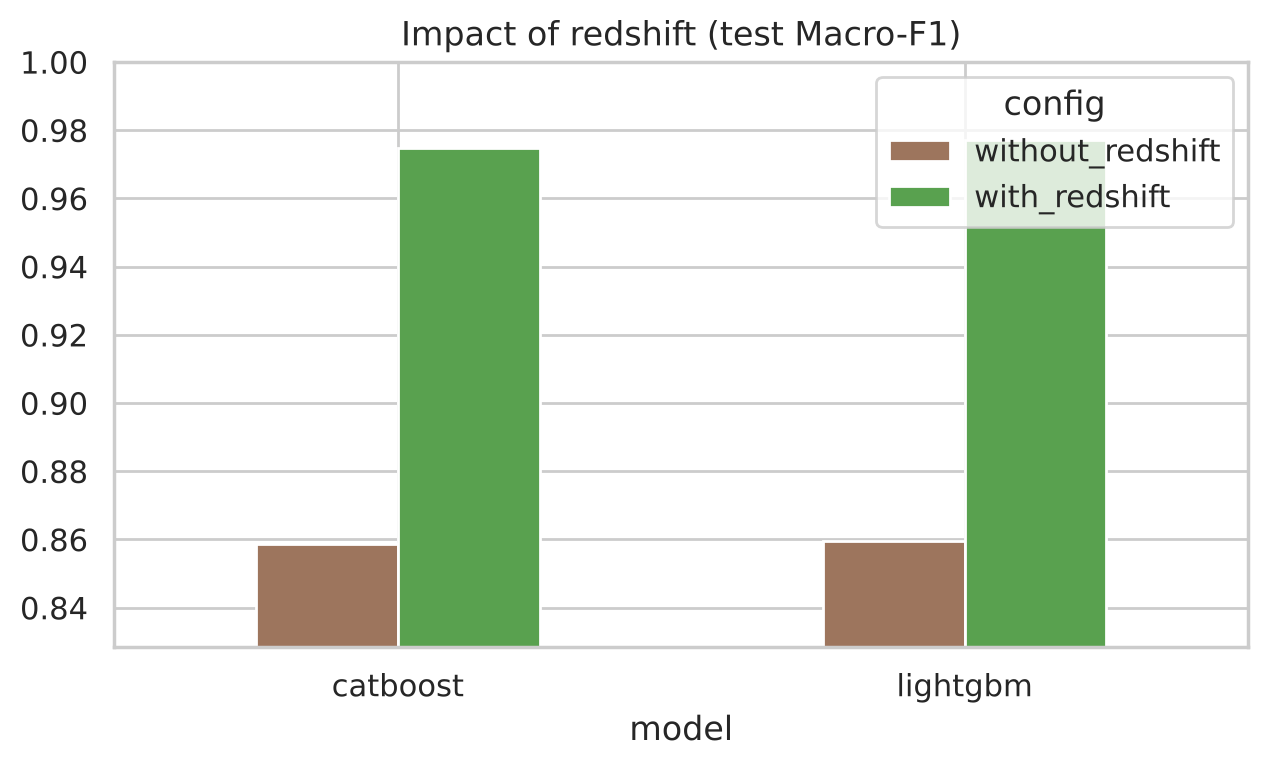

,config,model,f1_GALAXY,f1_QSO,f1_STAR
1,with_redshift,catboost,0.9818,0.9513,0.9915
3,with_redshift,lightgbm,0.9837,0.9516,0.9965
5,without_redshift,catboost,0.9359,0.8211,0.8187
7,without_redshift,lightgbm,0.9376,0.8202,0.8206


In [8]:
z = mt.query("split == 'test'").pivot(index="model", columns="config", values="macro_f1")
z["drop"] = z["with_redshift"] - z["without_redshift"]; display(z.round(4))
fig, ax = plt.subplots(figsize=(6.5, 4)); z[["without_redshift", "with_redshift"]].plot.bar(ax=ax, color=["#9d755d", "#59a14f"])
ax.set_ylim(z[["without_redshift", "with_redshift"]].values.min() - 0.03, 1.0); ax.set_title("Impact of redshift (test Macro-F1)"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(CMP / "redshift_impact.png", dpi=130); plt.show()
pc = mt.query("split == 'test'")[["config", "model"] + [f"f1_{c}" for c in CLASSES]]; pc.to_csv(CMP / "per_class_f1.csv", index=False); display(pc.round(4))

**Reading:** without redshift Macro-F1 falls from ~0.977 to ~0.86 for both algorithms, and the two models become almost indistinguishable - the information is simply no longer in the features, so no algorithm can recover it. The drop is concentrated in **QSO and STAR** (F1 ~0.82 for each without redshift): from photometry alone, quasars are easily confused with stars (both appear as unresolved point sources) and with galaxies. **Redshift is the single most important feature**, consistent with the EDA.

## 7. Save the tuning summary and the final model description

In [9]:
tune = pd.DataFrame([{"config": c, "model": n, "optuna_trials": r["n_trials"], "optuna_best_val_macro_f1": r["optuna_best_val_macro_f1"],
                      "optuna_seconds": r["optuna_seconds"], "final_fit_seconds": r["final_fit_seconds"],
                      "predict_seconds_test": r["predict_seconds_test"], "best_iteration": r["best_iteration"],
                      **{f"param_{k}": v for k, v in r["best_params"].items()}} for (c, n), r in R.items()])
tune.to_csv(CMP / "tuning_summary.csv", index=False); display(tune.set_index(["config", "model"]).T)

ext = "cbm" if winner == "catboost" else "joblib"
nz = {n: R[("without_redshift", n)]["test"]["macro_f1"] for n in ("catboost", "lightgbm")}
final = {"model": winner, "config": "with_redshift", "features": feats, "path": f"artifacts/models/with_redshift_{winner}.{ext}",
         "selection_rule": "highest test Macro-F1 among the two Optuna-tuned models", "test": W["test"], "val": W["val"],
         "bootstrap_vs_runner_up": boot, "explanation": explanation, "runner_up": runner, "best_params": W["best_params"],
         "classes": CLASSES, "photometry_only_best": max(nz, key=nz.get)}
(ART / "final_model.json").write_text(json.dumps(final, indent=2))
print("final model:", winner, "| photometry-only variant for the app:", final["photometry_only_best"])

config                    with_redshift             without_redshift           
model                          catboost    lightgbm         catboost   lightgbm
optuna_trials                        20          20               10         10
optuna_best_val_macro_f1       0.974201    0.975389         0.851798   0.853546
optuna_seconds               676.017332  118.350143       247.119555  96.260646
final_fit_seconds             52.554196    7.223472          7.21151  12.533406
predict_seconds_test           0.073955    1.304024         0.019582   2.907992
best_iteration                      620         301              219        289
param_learning_rate            0.049969    0.034582         0.218889   0.021147
param_depth                         9.0         NaN              7.0        NaN
param_l2_leaf_reg              1.427777         NaN         2.694687        NaN
param_random_strength          0.005406         NaN         0.001796        NaN
param_bagging_temperature      0.446871         NaN         0.310982        NaN
param_border_count                254.0         NaN            128.0        NaN
param_auto_class_weights           None         NaN             None        NaN
param_num_leaves                    NaN        49.0              NaN      234.0
param_max_depth                     NaN         9.0              NaN       13.0
param_min_child_samples             NaN         5.0              NaN        9.0
param_subsample                     NaN    0.530345              NaN   0.590912
param_colsample_bytree              NaN    0.656172              NaN   0.591702
param_reg_alpha                     NaN    0.119731              NaN    0.01648
param_reg_lambda                    NaN    0.491246              NaN    0.12561
param_class_weight                  NaN        None              NaN       None

final model: lightgbm | photometry-only variant for the app: lightgbm


## 8. MLflow: log the final model and register it
The `SDSS17-Final` experiment gets one run holding the selection rule, the winning parameters, the test metrics, the bootstrap interval, all comparison plots/tables, and the model, which is **registered** in the MLflow Model Registry as `sdss17-final-classifier`.

In [10]:
import mlflow.catboost, mlflow.lightgbm
mlflow_experiment("SDSS17-Final")
with mlflow.start_run(run_name="final_selected_model"):
    mlflow.set_tags({"algorithm": winner, "role": "final", "selection": final["selection_rule"]})
    mlflow.log_params({"final_model": winner, "feature_config": "with_redshift", **{f"hp_{k}": v for k, v in W["best_params"].items()}})
    mlflow.log_metrics({f"test_{k}": v for k, v in W["test"].items()})
    mlflow.log_metrics({"bootstrap_ci95_low": boot["ci95"][0], "bootstrap_ci95_high": boot["ci95"][1]})
    mlflow.log_artifact(str(ART / "final_model.json")); mlflow.log_artifacts(str(CMP), artifact_path="comparison")
    if winner == "catboost":
        mlflow.catboost.log_model(cb, name="model", registered_model_name="sdss17-final-classifier")
    else:
        mlflow.lightgbm.log_model(lg.booster_, name="model", registered_model_name="sdss17-final-classifier")

runs = mlflow.search_runs(search_all_experiments=True, output_format="pandas")
if "tags.mlflow.parentRunId" in runs: runs = runs[runs["tags.mlflow.parentRunId"].isna()]      # top-level runs only (trials are nested)
keep = [c for c in runs.columns if c in ("run_id", "experiment_id", "tags.mlflow.runName", "status", "start_time", "end_time", "tags.algorithm",
        "tags.feature_config", "tags.role", "metrics.optuna_best_val_macro_f1") or c.startswith(("metrics.test_", "metrics.val_", "params.hp_", "params.best_"))]
runs[keep].to_csv(ART / "mlflow_runs.csv", index=False)
display(runs[["tags.mlflow.runName", "tags.algorithm", "tags.feature_config", "metrics.test_macro_f1"]].sort_values("tags.mlflow.runName").reset_index(drop=True))

Successfully registered model 'sdss17-final-classifier'.
Created version '1' of model 'sdss17-final-classifier'.


,tags.mlflow.runName,tags.algorithm,tags.feature_config,metrics.test_macro_f1
0,eda,NaN,NaN,NaN
1,emeans_k3_with_redshift,E-Means,NaN,NaN
2,emeans_k3_without_redshift,E-Means,NaN,NaN
3,emeans_k_sweep,E-Means,NaN,NaN
4,final_selected_model,lightgbm,NaN,0.977253
5,with_redshift_catboost_optuna,catboost,with_redshift,0.974875
6,with_redshift_lightgbm_optuna,lightgbm,with_redshift,0.977253
7,without_redshift_catboost_optuna,catboost,without_redshift,0.858590
8,without_redshift_lightgbm_optuna,lightgbm,without_redshift,0.859470


## 9. Use the final model for predictions
The selected model is used for predictions (this is also what the Streamlit app does). Example: classify five random test objects.

In [11]:
final_model = cb if winner == "catboost" else lg
sample = S["test"].sample(5, random_state=1)
proba = final_model.predict_proba(sample[feats])
out = sample[["u", "g", "r", "i", "z", "redshift"]].copy().round(3)
out["true"] = [CLASSES[i] for i in sample["y"]]; out["predicted"] = [CLASSES[i] for i in proba.argmax(1)]
for i, c in enumerate(CLASSES): out[f"p_{c}"] = proba[:, i].round(3)
display(out)
print("Launch the interactive version with:  streamlit run app.py")

,u,g,r,i,z,redshift,true,predicted,p_GALAXY,p_QSO,p_STAR
7576,20.591,18.445,17.216,16.711,16.333,0.160,GALAXY,GALAXY,0.999,0.001,0.0
10509,20.737,20.521,20.337,20.394,20.380,1.376,QSO,QSO,0.002,0.998,0.0
4253,24.202,22.487,22.476,21.814,22.471,0.779,GALAXY,GALAXY,0.954,0.045,0.0
5150,19.674,18.200,17.391,16.902,16.595,0.072,GALAXY,GALAXY,0.996,0.004,0.0
506,22.775,21.746,21.855,21.926,20.925,2.227,QSO,QSO,0.001,0.999,0.0


Launch the interactive version with:  streamlit run app.py


## Conclusions
1. **Final model: LightGBM** (selected on test Macro-F1, per the specification) - accuracy ~0.980, Macro-F1 ~0.977.
2. CatBoost is a very close second; the gap is small but statistically distinguishable from zero. LightGBM also trains much faster.
3. **Redshift is decisive**: removing it drops Macro-F1 by ~12 points for both models; the lost performance is concentrated in QSO and STAR.
4. Remaining errors are dominated by QSO <-> GALAXY confusion.
5. Unsupervised E-Means (notebook 02) recovers the classes only weakly (ARI ~0.24) - the supervised models are required for this problem.

**Caveats:** selecting between two finalists on the test set (as specified) makes the winner's test score very slightly optimistic; Optuna budgets are modest (20 / 10 trials), so a larger search could change the ranking; the "why" in section 5 is a plausible explanation rather than a controlled experiment.